# Area in Drought

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a timeseries of the area in drought. 

## Setup and Settings

#### Load libraries

In [3]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

In [4]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):

    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.nan
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

#### General settings

In [5]:
ref_syyyy = 1991
ref_eyyyy = 2020
yyyy_start= 2005
yyyy_end  = 2026
indicator = "SPEI"
window    = 12
yyyy      = 2025
mm        = "09"
dataset   = "era5t"
stream    = "moda"
distribut = "genlogistic"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
cwd       = "/home/nejk/code/drought-on-demand"

In [6]:
dates = pd.date_range(start=f"{yyyy_start}-01-01",end=f"{yyyy_end}-01-01", freq='ME')
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]#[window:]
print(dates)
print(dates.size)

DatetimeIndex(['2005-01-31', '2005-02-28', '2005-03-31', '2005-04-30',
               '2005-05-31', '2005-06-30', '2005-07-31', '2005-08-31',
               '2005-09-30', '2005-10-31',
               ...
               '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30',
               '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31',
               '2025-11-30', '2025-12-31'],
              dtype='datetime64[ns]', length=252, freq='ME')
252


### Landmask and area

In [7]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']
# barren area mask: 1 - do NOT use, 0 - use!
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)

/usr/local/apps/python3/3.12.9-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.39.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


### Global mask

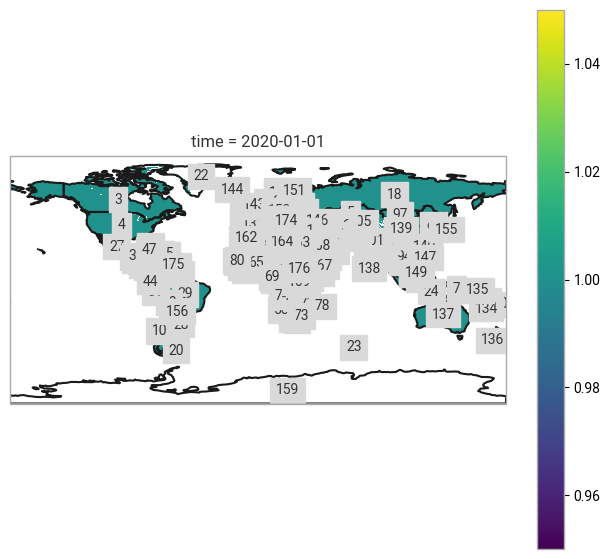

In [15]:
regionmask.defined_regions.natural_earth_v5_0_0.countries_110.plot()
mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110.mask(lmask.lon, lmask.lat)
mask = xr.where(mask >= 1, 1, np.nan)
mask = xr.where( (bmask['barren_mask'][0,:,:] == 1) , np.nan, mask)
mask.plot()

## ERA5-Drought

### Read drought index 

In [17]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq[:-3]:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
#print(filelist[:-8])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist)#.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
print(drought_index[window])

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 237, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2006-01-01T06:00:00 ... 2025-09-01T06:...
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    SPEI12   (time, lat, lon) float64 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/17)
    title:                   SPEI12
    description:             Drought Index: Standardized Drought Index calcul...
    Conventions:             CF-1.8
    history:                 Created 27/10/2024 12:22:08 using DRYFALL.
    institution:             European Centre for Medium-Range Weather Forecasts
    source:                  DRYFALL v1.0
    ...                      ...
    extent:                  -180,-90,180,90
    resolution:              0.25x0.25
    climate_start_date:      1991-01-01
    climate_end_date:        2020-12-31
    fr

## Mask for Mediterranean

### Mask data

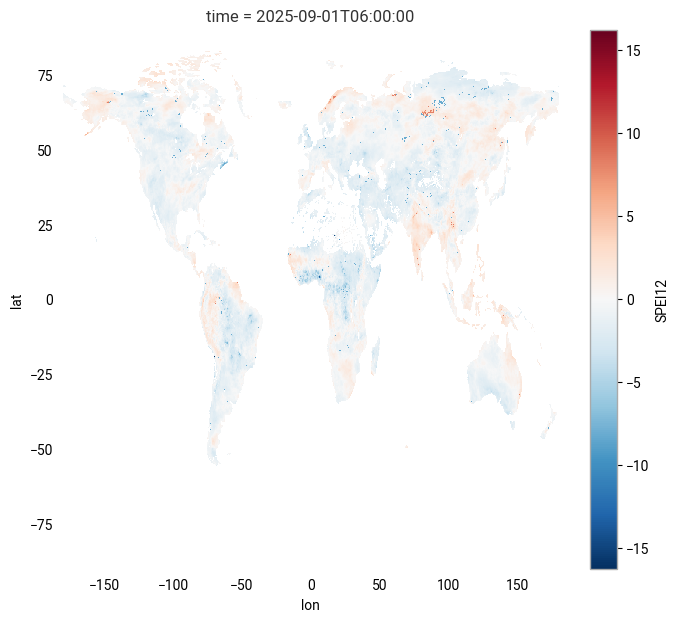

In [18]:
masked_drought_index = drought_index[window] * mask
masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)
masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()

area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
area_2d_adj = area_2d * lmask_frac
area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan

### Calculate area in drought

In [20]:
# calculate area in drought
area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
aid = {}

swindow=f"w{window}"
aid[swindow] = {}

for severity in ['moderate','severe','extreme','any']:
        
    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = -1

    rdi = masked_drought_index[f'{indicator}{window}']
    dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
    tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (mask*area_3d_adj).sum(dim=["lat", "lon"])
    aid[swindow][severity] = tmp.to_pandas() 

    del(tmp, dmask)

### Plot timeseries

In [22]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']

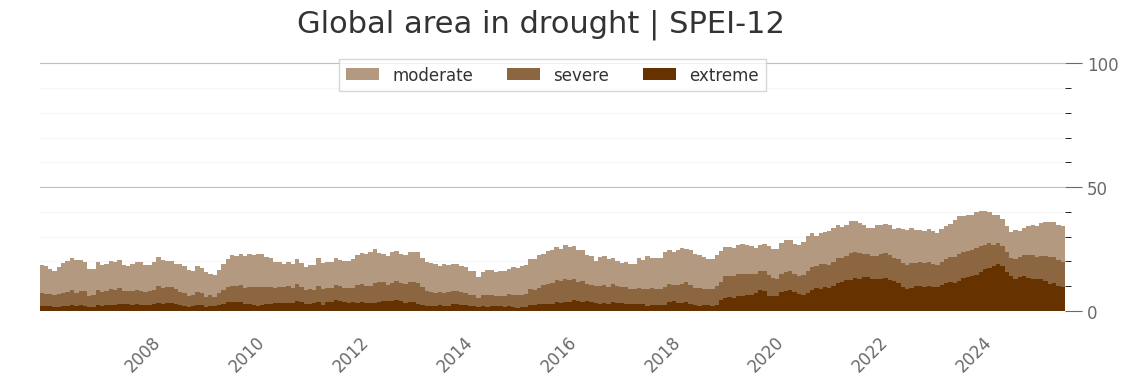

In [56]:
fig, ax1 = plt.subplots(1,1, figsize=(12,4))
fig.suptitle(f"Global area in drought | {indicator}-{window}", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 20}
plt.rc('font', **font)

severities = ['extreme','severe','moderate']
pidata2 = aid[f'w{window}']['extreme']#[f'{indicator}{window}']
pidata3 = aid[f'w{window}']['severe']#[f'{indicator}{window}']
pidata4 = aid[f'w{window}']['moderate']#[f'{indicator}{window}']
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
bottom = np.zeros(len(apidata.index))
for i in range(len(apidata.columns)):
    p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                alpha=1, 
                width=relativedelta.relativedelta(months=1), 
                label=severities[i], 
                bottom=bottom,
                align='edge')
    bottom += apidata.iloc[:,i]
ax1.set_ylabel("Area in drought [%]", size=18)
ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax1.tick_params(axis='y', colors='dimgray')
ax1.tick_params(axis='x', colors='dimgray')
ax1.xaxis.label.set_color('None')
ax1.yaxis.label.set_color('None')
ax1.minorticks_on()
ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
major_ticks = np.arange(0, 150, 50)
minor_ticks = np.arange(0, 150, 10)
ax1.set_yticks(major_ticks)
ax1.set_yticks(minor_ticks, minor=True)
ax1.yaxis.tick_right()
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=12)
ax1.set_axisbelow(True)
ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
ax1.set_ylim([0,105])
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    
plt.savefig(f"figures/Global_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

In [71]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.dates import YearLocator, DateFormatter

def plot_area_in_drought(aid, window, indicator, region="Global"):
    """
    Plots stacked area of global drought by severity over time.
    """

    # Severities and colors
    severities = ['extreme','severe','moderate']
    mycollisthex = ['#663300','#8c6640','#b29980']  # extreme -> severe -> moderate

    # Prepare data
    pidata2 = aid[f'w{window}']['extreme']
    pidata3 = aid[f'w{window}']['severe']
    pidata4 = aid[f'w{window}']['moderate']

    apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
    apidata.columns = severities

    x = apidata.index

    fig, ax = plt.subplots(1, 1, figsize=(12, 4))
    fig.suptitle(f"Global area in drought | {indicator}-{window} months", fontsize=18, weight='bold')
    plt.tight_layout(pad=3.0)
    fig.subplots_adjust(top=0.85)

    # Stackplot with zorder=0 so axes/ticks are on top
    ax.stackplot(x, [apidata[sev] for sev in severities],
                 labels=severities, colors=mycollisthex, zorder=0)

    # Y-axis
    ax.set_ylabel("Area in drought [%]", fontsize=14)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_locator(plt.MultipleLocator(20))
    ax.yaxis.set_minor_locator(plt.MultipleLocator(5))
    ax.yaxis.grid(which='major', linestyle='-', color='gray', alpha=0.5, zorder=1)
    ax.yaxis.grid(which='minor', linestyle=':', color='lightgray', alpha=0.3, zorder=1)

    # X-axis
    ax.xaxis.set_major_locator(YearLocator())
    ax.xaxis.set_major_formatter(DateFormatter('%Y'))
    ax.set_xlim(x.min(), x.max())
    ax.tick_params(axis='x', rotation=45, zorder=2)

    # Spines and legend
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)
    ax.set_axisbelow(False)  # ensures ticks and spines are above stackplot
    ax.legend(ncol=3, loc='upper center', fontsize=12)

    plt.show()


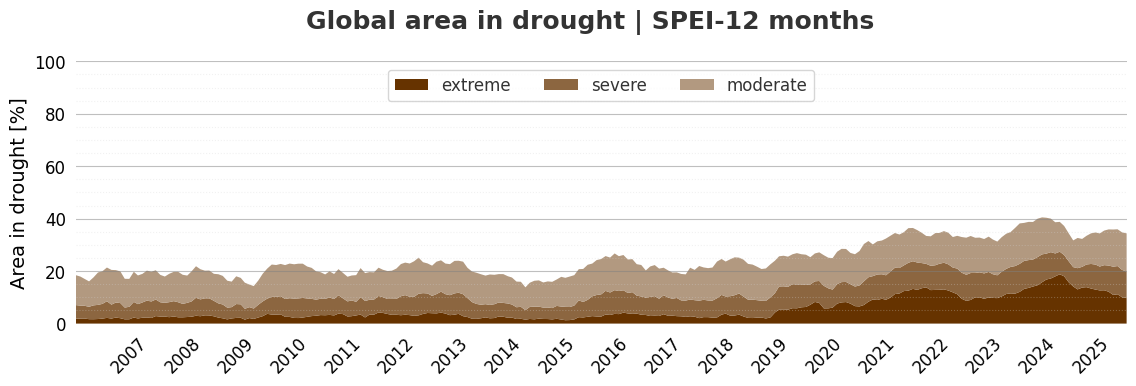

In [72]:
#plot_area_in_drought(aid, indicator, window, 'Global', mycollisthex)
plot_area_in_drought(aid, window, indicator, region="Global")